# Lending Club Loan Data Analysis

## Objective: 
Create a model that predicts whether or not a loan will be default using the historical data.

### Problem Statement:  
For companies like Lending Club correctly predicting whether or not a loan will be a default is very important. In this project, using the historical data from 2007 to 2015, you have to build a deep learning model to predict the chance of default for future loans. As you will see later this dataset is highly imbalanced and includes a lot of features that make this problem more challenging.


# Business Questions to Answer (Before Any Model)

1. Which loan purposes default the most?
2. Does FICO score separate defaulters from non-defaulters?
3. Are higher interest rates linked to more defaults?
4. Do borrowers who fail the credit policy default more?
5. Do recent credit inquiries signal risk?

# Step 1 : Load & import dataset

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [14]:
df = pd.read_csv("c:/Desktop/Desktop/Microsoft_AI_Engineering/deep_learning/Lending_loans/Lending_Dataset/loan_data (2).csv")
df

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9573,0,all_other,0.1461,344.76,12.180755,10.39,672,10474.000000,215372,82.1,2,0,0,1
9574,0,all_other,0.1253,257.70,11.141862,0.21,722,4380.000000,184,1.1,5,0,0,1
9575,0,debt_consolidation,0.1071,97.81,10.596635,13.09,687,3450.041667,10036,82.9,8,0,0,1
9576,0,home_improvement,0.1600,351.58,10.819778,19.18,692,1800.000000,0,3.2,5,0,0,1


In [15]:
df.head(10)

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0
5,1,credit_card,0.0788,125.13,11.904968,16.98,727,6120.041667,50807,51.0,0,0,0,0
6,1,debt_consolidation,0.1496,194.02,10.714418,4.00,667,3180.041667,3839,76.8,0,0,1,1
7,1,all_other,0.1114,131.22,11.002100,11.08,722,5116.000000,24220,68.6,0,0,0,1
8,1,home_improvement,0.1134,87.19,11.407565,17.25,682,3989.000000,69909,51.1,1,0,0,0
9,1,debt_consolidation,0.1221,84.12,10.203592,10.00,707,2730.041667,5630,23.0,1,0,0,0


In [16]:
# Function to explore the dataset

def explore_data(df):
    print(f"-"*15, "INFO","-"*15)
    print(df.info())

    print(f"-"*15, "DESCRIBE","-"*15)
    display(df.describe())

    print(f"-"*15, "CHECK NULLS","-"*15)
    print(df.isnull().sum())

    print(f"-"*15, "CHECK DUPLICATES","-"*15)
    print(df.duplicated().sum())

    print(f"-"*15, "SHAPE OF DATA","-"*15)
    print(df.shape)

explore_data(df)

--------------- INFO ---------------
<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.0 MB
None
--------------- DESCRIBE -----------

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


--------------- CHECK NULLS ---------------
credit.policy        0
purpose              0
int.rate             0
installment          0
log.annual.inc       0
dti                  0
fico                 0
days.with.cr.line    0
revol.bal            0
revol.util           0
inq.last.6mths       0
delinq.2yrs          0
pub.rec              0
not.fully.paid       0
dtype: int64
--------------- CHECK DUPLICATES ---------------
0
--------------- SHAPE OF DATA ---------------
(9578, 14)


# Step 2: Data preprocess

In [17]:
# # only 1 col is str (purpose of loan ) -- Encoding
# df = pd.get_dummies(df, columns=['purpose'], drop_first=True, dtype=int)
# df

# Step 3: EDA

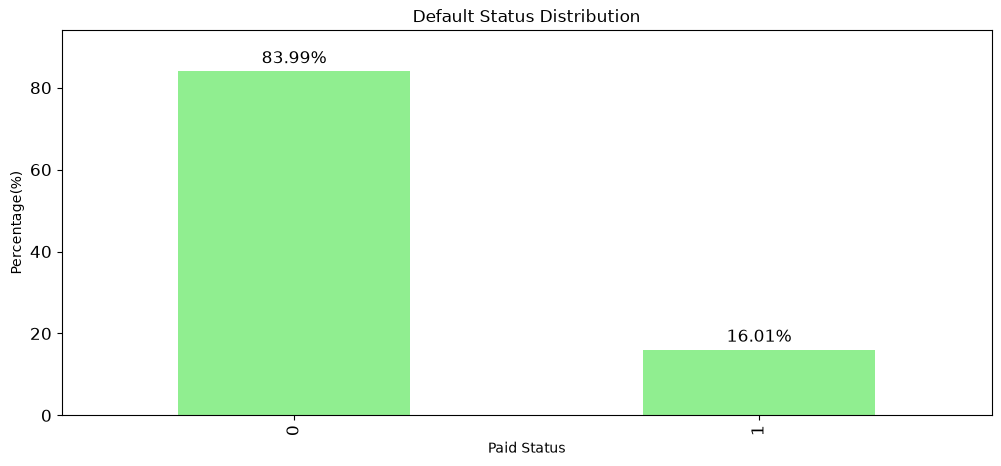

In [ ]:
# Get the class distribution of target
not_paid = df['not.fully.paid'].value_counts(normalize=True)*100

ax = not_paid.plot(kind='bar', figsize=(12,5), fontsize=12, color='lightgreen')

# % sign on top of bar
ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=3, fontsize=12)

# padding so the labels don't get cut off at the top
ax.set_ylim(0, not_paid.max() + 10)

ax.set_xlabel("Paid Status")
ax.set_ylabel("Percentage(%)")
ax.set_title("Default Status Distribution")
plt.show()

# This plot shows:
fig, axes = plt.subplots(4,2, figsize=(18,24))
fig.subplots_adjust(hspace=0.6, wspace=0.5)# About 83.99% did not paid the full loan & only 16.01% paid the loan

Text(0, 0.5, 'Default rate')

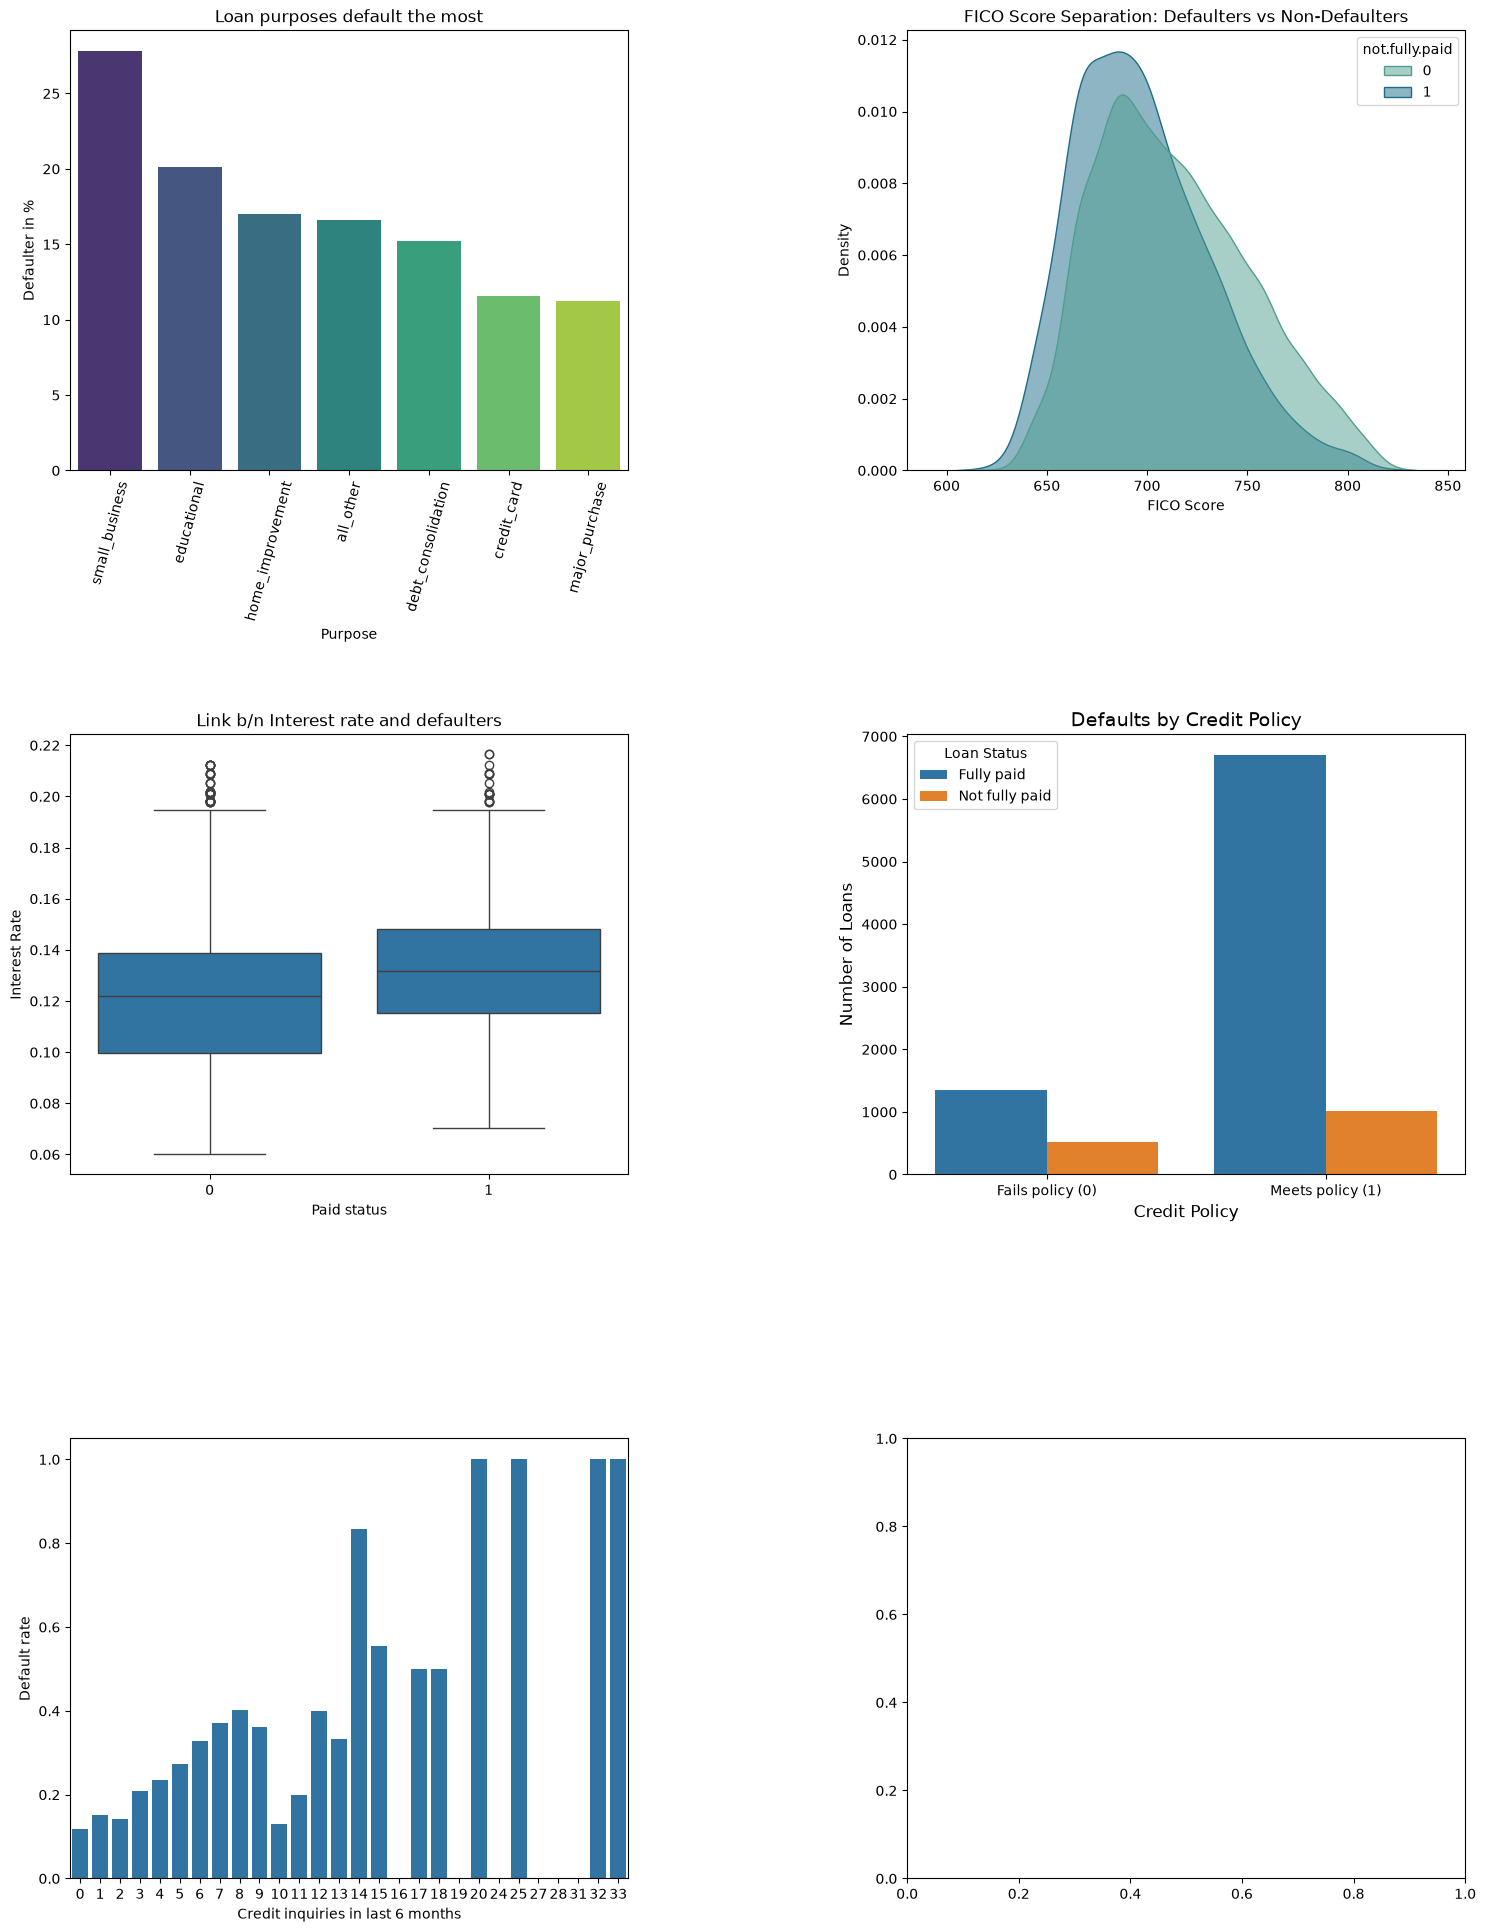

In [ ]:
fig, axes = plt.subplots(3,2, figsize=(18,24))
fig.subplots_adjust(hspace=0.6, wspace=0.5)

# 1. Which loan purposes default the most?
most_defaulters = df.groupby('purpose')['not.fully.paid'].mean().sort_values(ascending=False)
sns.barplot(x=most_defaulters.index, y=most_defaulters.values*100, hue=most_defaulters.index, palette='viridis', legend=False, ax=axes[0,0]) 
axes[0,0].set_xlabel('Purpose',fontsize=10)
axes[0,0].set_ylabel('Defaulter in %',fontsize=10)
axes[0,0].set_title('Loan purposes default the most', fontsize=12)
axes[0,0].tick_params(axis='x', rotation=75)

# 2. Can a FICO score successfully tell the difference between a "safe" borrower and a "risky" borrower?
sns.kdeplot(data=df, x='fico', hue='not.fully.paid', fill=True, common_norm=False, palette='crest', alpha=0.5, ax=axes[0,1])
axes[0,1].set_title('FICO Score Separation: Defaulters vs Non-Defaulters', fontsize=12)
axes[0,1].set_xlabel('FICO Score', fontsize=10)
axes[0,1].set_ylabel('Density', fontsize=10)

# 3. Are higher interest rates linked to more defaults?
sns.boxplot(data=df, x='not.fully.paid', y='int.rate', ax=axes[1,0])
axes[1,0].set_xlabel('Paid status', fontsize=10)
axes[1,0].set_ylabel('Interest Rate',fontsize=10)
axes[1,0].set_title('Link b/n Interest rate and defaulters')

# 4. Do borrowers who fail the credit policy default more?
sns.countplot(data=df, x="credit.policy", hue="not.fully.paid", ax=axes[1,1])
axes[1,1].set_title('Defaults by Credit Policy', fontsize=14)
axes[1,1].set_xlabel('Credit Policy', fontsize=12)
axes[1,1].set_ylabel('Number of Loans', fontsize=12)
axes[1,1].set_xticks([0, 1])
axes[1,1].set_xticklabels(['Fails policy (0)', 'Meets policy (1)'])
axes[1,1].legend(title='Loan Status', labels=['Fully paid', 'Not fully paid'])

# 5. Do recent credit inquiries signal risk?
inq_rate = df.groupby(df['inq.last.6mths'].clip(upper=6))['not.fully.paid'].mean()
sns.barplot(x=inq_rate.index, y=inq_rate.values, ax=axes[2,0])
axes[2,0].set_xlabel('Credit inquiries in last 6 months')
axes[2,0].set_ylabel('Default rate')
axes[2,0].set_title('Inquire for credits')

In [52]:
df['inq.last.6mths'].nunique()

28